# Stage 7 delay topology and phase-information test

## tl;dr

Decision: drop. Claim: calibrated_negative_result. Evaluation BH rejections: phase-randomized=0/12, IAAFT=0/12. Combined-model improvement over classical=-0.136.


## Context & Methods

Governed run `TA-S07-DELAY-R001` uses 24 locked simulation cells, unreduced VR persistence, paired PSD-preserving surrogates, and an untouched even-cell evaluation split.

### Key Assumptions

PCA is visualization-only; every missing delay window is removed; the result applies only to the tested simulation regime.


## Data

Load the sealed Stage 7 result tables and gate record.


In [1]:
import csv
import json
from pathlib import Path

root = Path('results/stage7')
with (root / 'phase_tests.csv').open() as handle:
    phase_tests = list(csv.DictReader(handle))
with (root / 'predictive_ablation.csv').open() as handle:
    ablation = list(csv.DictReader(handle))
decision = json.loads(Path('reports/stage7/G7_ACCEPTANCE.json').read_text())
print(decision['decision'], decision['claim'], len(phase_tests), len(ablation))


drop calibrated_negative_result 48 3


## Results

Recompute the evaluation rejection counts and predictive increment from the serialized evidence.


In [2]:
evaluation = [row for row in phase_tests if row['role'] == 'evaluation']
for family in ('phase_randomized', 'iaaft'):
    selected = [row for row in evaluation if row['surrogate_family'] == family]
    print(family, sum(row['bh_rejected'] == 'true' for row in selected), '/', len(selected))
combined = next(row for row in ablation if row['method'] == 'combined')
print('combined improvement', combined['improvement_over_classical'])


phase_randomized 0 / 12
iaaft 0 / 12
combined improvement -0.1357201125


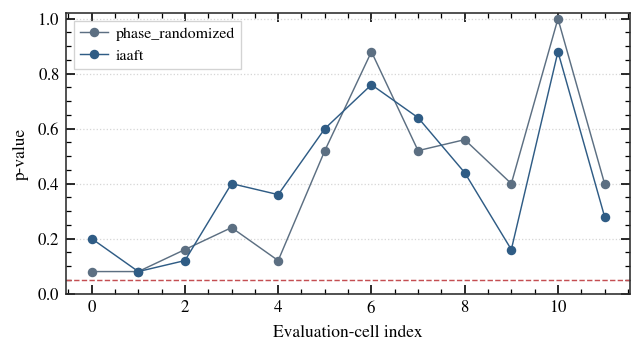

In [3]:
import matplotlib.pyplot as plt

from topoastero.style import data_color, style_axes, topoastero_style

with topoastero_style():
    fig, ax = plt.subplots(figsize=(5.6, 2.8))
    for family, color in zip(
        ('phase_randomized', 'iaaft'),
        (data_color('spectrum'), data_color('background')),
        strict=True,
    ):
        values = [float(row['pvalue']) for row in evaluation if row['surrogate_family'] == family]
        ax.plot(
            range(len(values)),
            values,
            marker='o',
            linewidth=0.8,
            label=family,
            color=color,
        )
    ax.axhline(0.05, color=data_color('threshold'), linestyle='--', linewidth=0.8)
    style_axes(ax, xlabel='Evaluation-cell index', ylabel='p-value', legend=True, ylim=(0, 1.02))
    plt.show()


## Takeaways

Decision: drop. Claim: calibrated_negative_result. Evaluation BH rejections: phase-randomized=0/12, IAAFT=0/12. Combined-model improvement over classical=-0.136. The full audit remains in `reports/stage7/`.
